# 03 — Exploratory Data Analysis (EDA)

## Bank Marketing Dataset

**Goal:** Explore the data to discover patterns, trends, and relationships between the client profiles and their subscription to the term deposit (`y`).

**Dataset:** The cleaned dataset (`bank_clean.csv`) containing 45,211 clients.

**Plan:**
- **Univariate Analysis:** Study one variable at a time (Age, Job, Education, Balance, Campaign).
- **Bivariate Analysis:** Cross-analyze variables with the target (`y`). For example: Does age influence subscription? Do retired people subscribe more?
- **Correlations:** Check which numerical variables are linked together.

**Author:** Fatima Azzahra
**Date:** 2026-10-09

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)


df = pd.read_csv('../data/bank_clean.csv')

print("Clean data loaded for EDA ✅")
print("Shape:", df.shape)

Clean data loaded for EDA ✅
Shape: (45211, 17)


**Group A: Univariate Analysis**

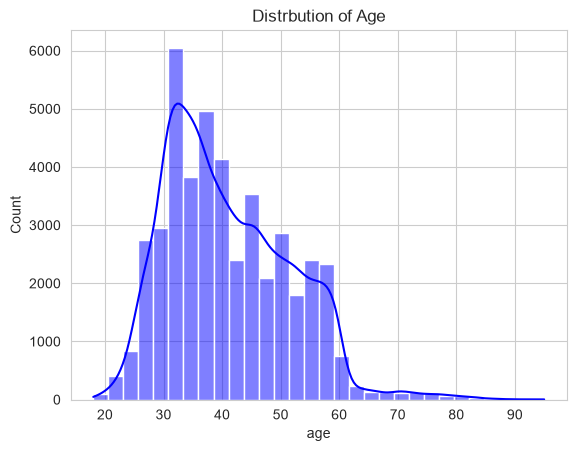

In [2]:
# Distribution of clients age 
sns.histplot(df['age'], bins=30, kde=True, color='blue')
plt.title('Distrbution of Age')
plt.show()

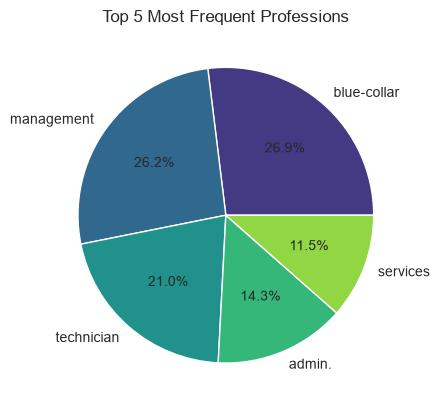

In [3]:
#  the 5 most frequent professions 
most_frequent_professions = df['job'].value_counts().head(5)
plt.pie(most_frequent_professions.values , 
         labels=most_frequent_professions.index , 
         autopct='%1.1f%%' ,
         colors=sns.color_palette('viridis', 5)) 
plt.title('Top 5 Most Frequent Professions')
plt.show()

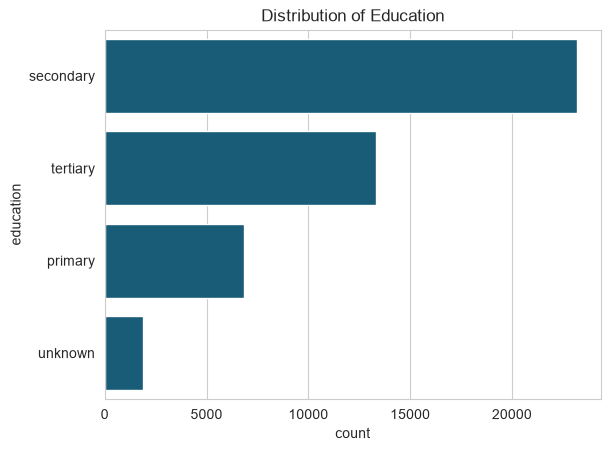

In [4]:
# Distribution of education 
sns.countplot(y=df['education'], color='#086288', order=df['education'].value_counts().index)
plt.title('Distribution of Education')
plt.show()

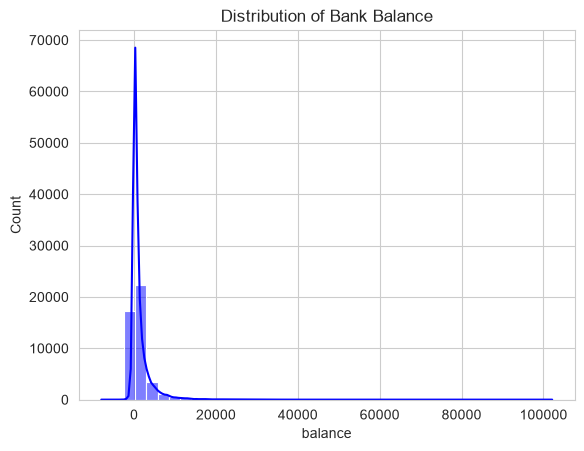

In [5]:
# distribution of bank balance 
sns.histplot(df['balance'] , bins = 40 , kde = True , color = 'Blue' )
plt.title('Distribution of Bank Balance')
plt.show()

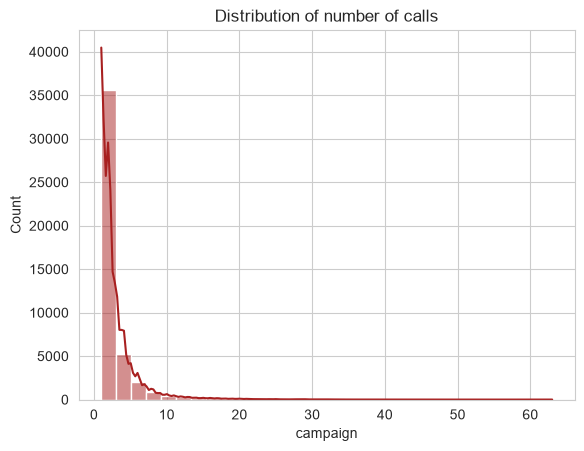

In [6]:
# Distribution of number of calls 
sns.histplot(df['campaign'] , bins = 30 , kde = True , color = '#A82020')
plt.title('Distribution of number of calls')
plt.show()

**Group B: Bivariate Analysis**

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\1898176553.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='age_group', y='y_numeric', data=df, palette='Blues', errorbar=None)


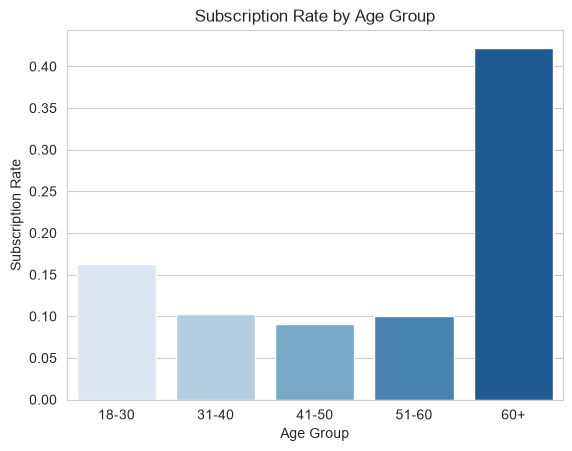

In [7]:
# Does the subscription rate vary by age group? (18-30, 31-40, 41-50, 51-60, 60+) 
df['age_group'] = pd.cut(df['age'] ,bins= [17,30,40,50,60,100]  , labels = ['18-30', '31-40', '41-50', '51-60', '60+'])
df['y_numeric'] = df['y'].map({'yes' : 1 , 'no': 0}) 
sns.barplot(x='age_group', y='y_numeric', data=df, palette='Blues', errorbar=None)

plt.title('Subscription Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Subscription Rate')

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\3546498941.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='job' , y='y_numeric' , data=df,  palette ='viridis' , errorbar= None)


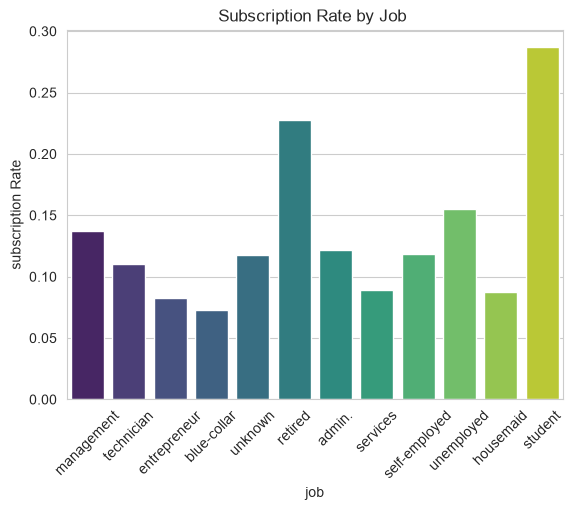

In [8]:
# Which profession has the highest subscription rate? 
sns.barplot(x='job' , y='y_numeric' , data=df,  palette ='viridis' , errorbar= None) 
plt.title('Subscription Rate by Job ')
plt.xlabel('job')
plt.ylabel('subscription Rate')
plt.xticks(rotation=45)
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\264282728.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'balance group' , y='y_numeric' , data=df , palette= 'Blues' , errorbar= None)


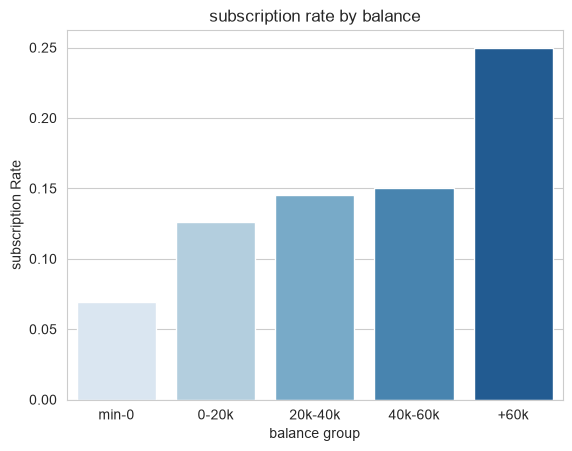

In [9]:
#  Do clients with a high balance subscribe more? 
df['balance group']=pd.cut(df['balance'] ,bins=[df['balance'].min() ,0,20000,40000,60000, df['balance'].max()], labels= ['min-0' , '0-20k', '20k-40k','40k-60k','+60k'])
sns.barplot(x= 'balance group' , y='y_numeric' , data=df , palette= 'Blues' , errorbar= None) 
plt.title('subscription rate by balance')
plt.xlabel('balance group')
plt.ylabel('subscription Rate')
plt.show()


The graph shows a clear upward trend: the higher the bank balance, the higher the subscription rate. 
- Clients with a negative balance (overdraft) have a very low subscription rate (~6%).
- Clients with more than 60,000€ have the highest subscription rate (~25%).

**Business Insight:** Wealthy clients are the ideal target. The bank should prioritize them in its marketing campaigns, as they are much more likely to subscribe to a term deposit.

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\583878259.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'housing' , y='y_numeric' , data=df , palette= 'Reds' , errorbar= None)


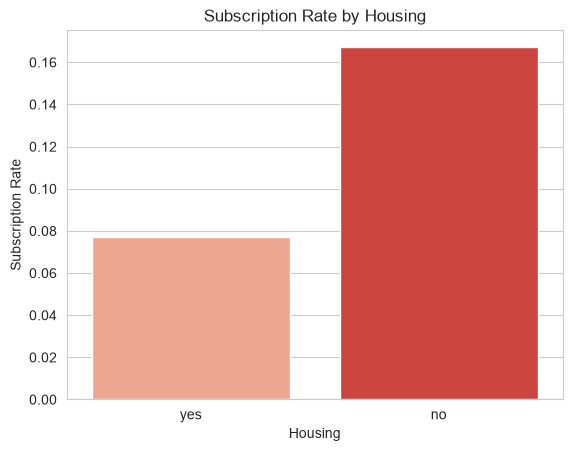

In [10]:
# Do clients with a housing loan subscribe less? 
sns.barplot(x= 'housing' , y='y_numeric' , data=df , palette= 'Reds' , errorbar= None) 
plt.title('Subscription Rate by Housing')
plt.xlabel('Housing')
plt.ylabel('Subscription Rate')
plt.show()

Clients without a housing loan are twice as likely to subscribe. The bank should target clients who are not burdened by a mortgage.

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\4260170173.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'loan' , y='y_numeric' , data=df , palette= 'vlag' , errorbar= None)


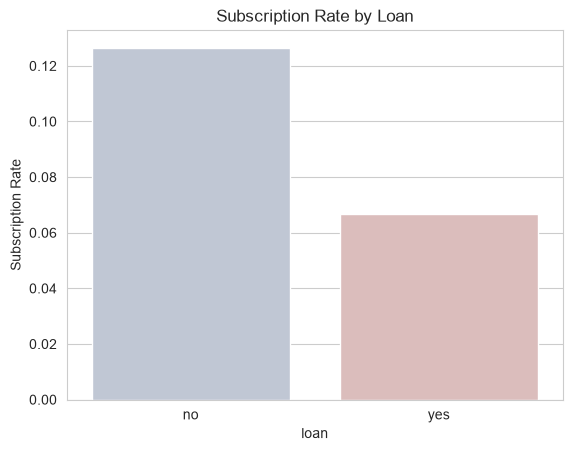

In [11]:
# Do clients with a personal loan subscribe less? 
sns.barplot(x= 'loan' , y='y_numeric' , data=df , palette= 'vlag' , errorbar= None) 
plt.title('Subscription Rate by Loan')
plt.xlabel('loan')
plt.ylabel('Subscription Rate')
plt.show() 

Having a personal loan significantly reduces the chances of subscribing. Clients without a personal loan have a subscription rate of ~12.5%, compared to only ~6.5% for those with a personal loan. 

**Business Insight:** Just like with housing loans, personal debt makes clients more cautious. The bank should prioritize clients with no personal loans, as they have more available cash flow to invest in a term deposit.

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\3266603319.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'campaign group' , y='y_numeric' , data=df , palette= 'Blues' , errorbar= None)


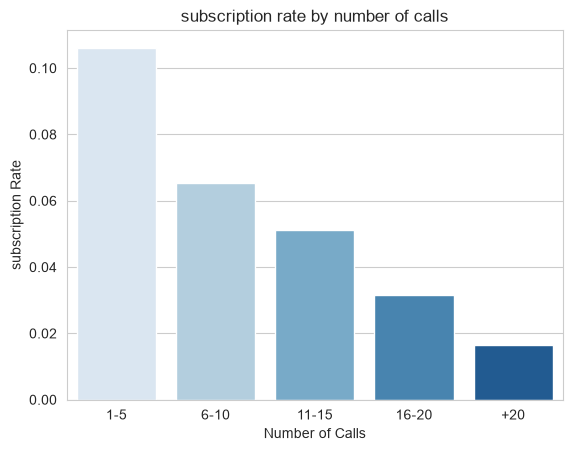

In [12]:
# Does contacting a client multiple times increase the chances of subscription? 
df['campaign group']= pd.cut(df['campaign'] , bins= [1,5,10,15,20,df['campaign'].max()] , labels= ['1-5', '6-10','11-15','16-20','+20'])
sns.barplot(x= 'campaign group' , y='y_numeric' , data=df , palette= 'Blues' , errorbar= None) 
plt.title('subscription rate by number of calls')
plt.xlabel('Number of Calls')
plt.ylabel('subscription Rate')
plt.show()

The graph shows a clear downward trend. 
Clients called 1 to 5 times have the highest subscription rate (~10.5%). However, the more the bank calls a client, the lower the subscription rate becomes. Clients called more than 20 times have a very low subscription rate (under 2%).

**Business Insight:** Telemarketing harassment drives clients away. The bank should limit the number of calls to a maximum of 3 or 4 per client to avoid losing them. Quality is better than quantity.

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\3389953695.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'poutcome', y='y_numeric' , data=df , palette= 'Blues' , errorbar= None , ax=axes[0])
C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\3389953695.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='poutcome' , y='y_numeric' , data=df[df['poutcome'] != 'unknown'] , palette= 'Greens' , errorbar=None ,ax=axes[1])


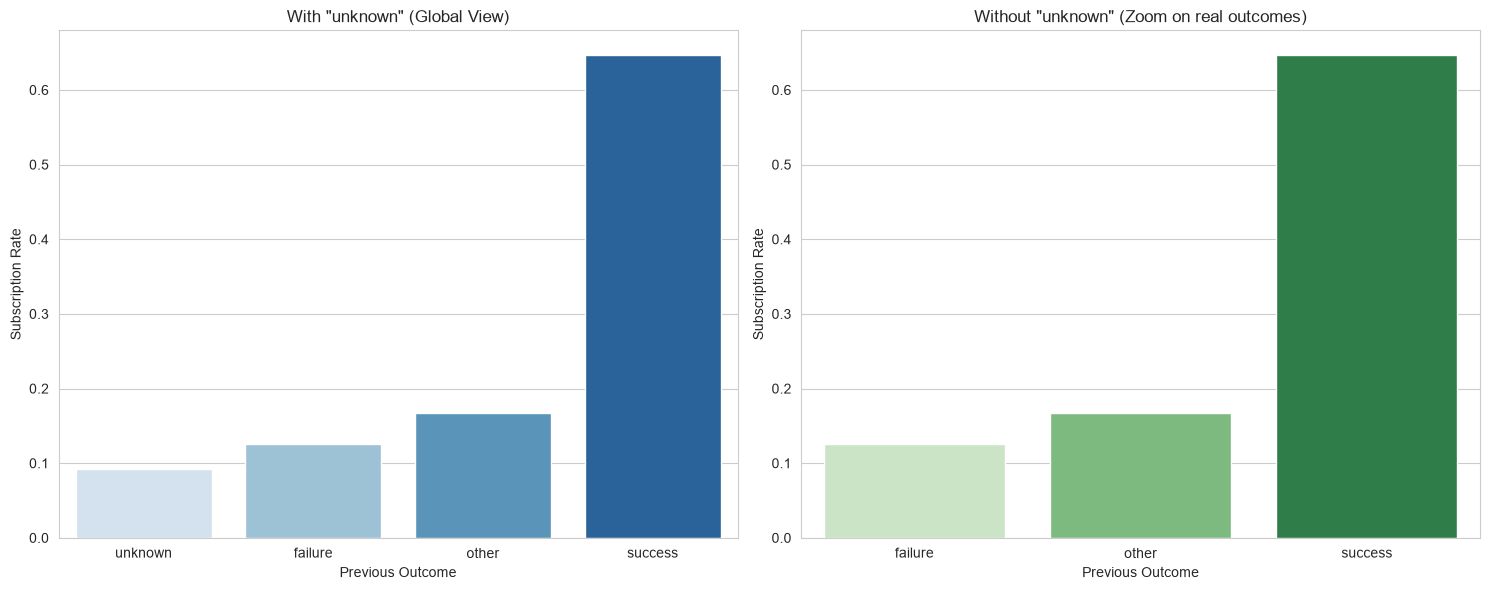

In [13]:
# Does the outcome of the previous campaign influence the current subscription? 

fig, axes = plt.subplots(1,2 , figsize = (15,6))

#graph 1 : with unknown
sns.barplot(x= 'poutcome', y='y_numeric' , data=df , palette= 'Blues' , errorbar= None , ax=axes[0]) 
axes[0].set_title('With "unknown" (Global View)')
axes[0].set_xlabel('Previous Outcome')
axes[0].set_ylabel('Subscription Rate')

#graph 2 : without unkonwn 
sns.barplot(x='poutcome' , y='y_numeric' , data=df[df['poutcome'] != 'unknown'] , palette= 'Greens' , errorbar=None ,ax=axes[1])
axes[1].set_title('Without "unknown" (Zoom on real outcomes)')
axes[1].set_xlabel('Previous Outcome')
axes[1].set_ylabel('Subscription Rate') 

plt.tight_layout()

plt.show()

The previous campaign outcome is a massive predictor. 
As seen in the global view, clients whose previous campaign was a `success` have a staggering **65%** subscription rate. 

To see the real impact without the "unknown" group (clients never contacted before) skewing the scale, we plotted the zoomed view (right). It clearly shows that a past `success` makes a client 5 times more likely to subscribe compared to a past `failure` (~12%) or `other` (~16%).

**Business Insight:** The bank should absolutely prioritize clients who said "yes" in a previous campaign. This is the highest ROI target.

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\235728465.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= 'month' , y='y_numeric' , data=df ,order = month_order, palette= 'rocket' , errorbar= None)


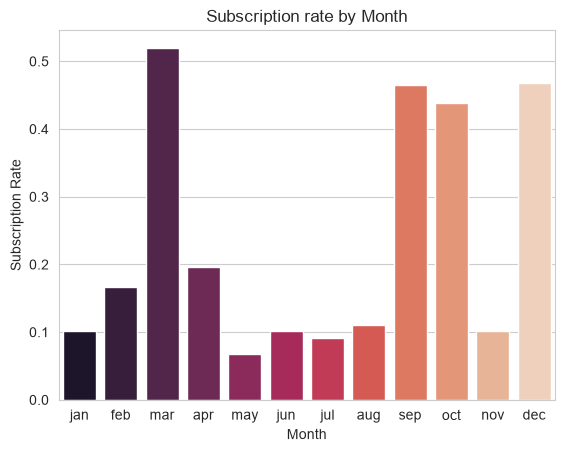

In [14]:
# Does the month of contact influence subscription?
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

sns.barplot(x= 'month' , y='y_numeric' , data=df ,order = month_order, palette= 'rocket' , errorbar= None) 
plt.title('Subscription rate by Month')
plt.xlabel('Month')
plt.ylabel('Subscription Rate')
plt.show()

The month of the campaign has a massive impact on the success rate. 
- **High conversion months:** March (~52%), September (~47%), October (~44%), and December (~47%). 
- **Low conversion months:** May is the worst month by far (~6%), followed by June, July, and August (all under 11%).

**Business Insight:** Timing is everything. The bank should concentrate its marketing campaigns during March, September, October, and December (likely periods of financial bonuses, end of quarters, or tax season). Conversely, the bank should drastically reduce its efforts in May and during the summer holidays.

**Group C: Correlations**

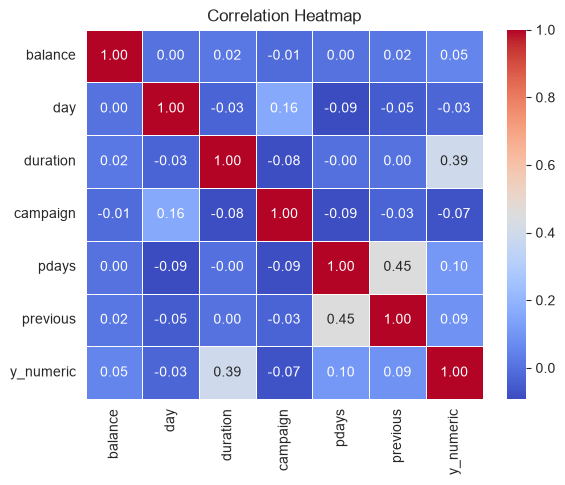

In [22]:
# Which numeric variables are correlated with each other? 
correlation = df[['balance' , 'day' , 'duration' , 'campaign' , 'pdays' , 'previous' , 'y_numeric']].corr()
sns.heatmap(correlation ,annot=True , cmap= 'coolwarm' , fmt=".2f", linewidths=0.5 )
plt.title("Correlation Heatmap")
plt.show() 

C:\Users\DELL\AppData\Local\Temp\ipykernel_15560\1179654875.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data =df , x = 'y' , y='duration' , palette ='Set2' , width = 0.5)


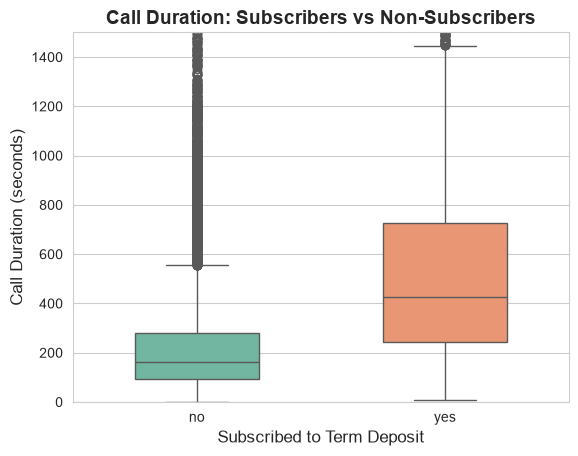

In [27]:
# Is the call duration (duration) correlated with subscription? 
sns.boxplot(data =df , x = 'y' , y='duration' , palette ='Set2' , width = 0.5)
plt.title("Call Duration: Subscribers vs Non-Subscribers", fontsize=14, fontweight='bold')
plt.xlabel("Subscribed to Term Deposit", fontsize=12)
plt.ylabel("Call Duration (seconds)", fontsize=12)
plt.ylim(0, 1500)
plt.show()

The boxplot shows a clear difference in call duration between the two groups. 
- The median call duration for clients who said "no" is around 150 seconds (2.5 minutes).
- The median call duration for clients who said "yes" is around 420 seconds (7 minutes).

**Business Insight:** Time is a key indicator of interest. Clients who stay on the phone longer are much more likely to subscribe. A short call almost always results in a rejection. Sales agents should be trained to engage clients in longer conversations.

**Group D: Insights** 


 5 Key Insights:**
1. **Call Duration:** It is the most important numerical indicator. Clients who say "yes" stay on the phone 3 times longer than those who say "no".
2. **Age Paradox:** While the majority of clients are 30-40 years old, the highest subscription rate comes from the 60+ age group.
3. **Top Profession:** Students have the highest subscription rate (~30%), followed by retired people. 
4. **Wealth:** Clients with a balance over 60,000€ are 4 times more likely to subscribe than those with a negative balance.
5. **Campaign Fatigue:** Calling a client too many times has a negative effect. The more calls, the lower the subscription rate.

**Ideal Client Profile (Who says YES?):**
A student or retired person, over 60 years old, with a high bank balance (>60k€), who does not have a housing or personal loan, contacted in March, September, or December, and who stays on the phone for a long time. If they had a successful previous campaign, the chances are even higher.

**Unlikely Client Profile (Who says NO?):**
A blue-collar worker, around 40 years old, with a negative or low bank balance, who has a housing loan and a personal loan. They are usually contacted in May, they don't stay long on the phone, and they have been called many times before (campaign fatigue).